<a href="https://colab.research.google.com/github/Vedhasripampati/diagnose-crop-disease-with-ML/blob/main/aiml_microproject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
files.upload()   # select kaggle.json

Saving kaggle (1).json to kaggle (1).json


{'kaggle (1).json': b'{"username":"vedhasripampati","key":"bbda5c88632525a2593e761cbe475e1f"}'}

In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle*.json ~/.kaggle/kaggle.json
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d abdallahalidev/plantvillage-dataset
!unzip -q plantvillage-dataset.zip -d data

Dataset URL: https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset
License(s): CC-BY-NC-SA-4.0
100% 2.04G/2.04G [00:17<00:00, 127MB/s]



In [ ]:
import numpy as np, cv2, os, json
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models

In [ ]:
EPOCHS = 10
INIT_LR = 1e-3
BS = 32
IMAGE_SIZE = (128, 128)
DATA_DIR = "data/plantvillage dataset/color"
print(len(os.listdir(DATA_DIR)), "classes found")

38 classes found


In [ ]:
def load_and_preprocess_images(data_dir, max_per_class=100):
    data, labels = [], []
    for class_name in sorted(os.listdir(data_dir)):
        class_dir = os.path.join(data_dir, class_name)
        if not os.path.isdir(class_dir):
            continue
        for image_file in os.listdir(class_dir)[:max_per_class]:
            image = cv2.imread(os.path.join(class_dir, image_file))
            if image is None:
                continue
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            image = cv2.resize(image, IMAGE_SIZE)
            data.append(image.astype("float32") / 255.0)
            labels.append(class_name)
    return np.array(data), np.array(labels)

In [ ]:
X, y = load_and_preprocess_images(DATA_DIR)
le = LabelEncoder()
y = le.fit_transform(y)
print(X.shape, len(le.classes_))

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

(3800, 128, 128, 3) 38


In [ ]:
datagen = ImageDataGenerator(
    rotation_range=20, width_shift_range=0.1, height_shift_range=0.1,
    zoom_range=0.1, horizontal_flip=True, fill_mode='nearest')

In [ ]:
base = MobileNetV2(input_shape=(*IMAGE_SIZE, 3), include_top=False, weights='imagenet')
base.trainable = False

model = models.Sequential([
    layers.Input(shape=(*IMAGE_SIZE, 3)),
    layers.Rescaling(2.0, offset=-1.0),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(len(le.classes_), activation='softmax')
])
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,306,662 (8.80 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
model.compile(loss='sparse_categorical_crossentropy',
              optimizer=Adam(learning_rate=INIT_LR),
              metrics=['accuracy'])

In [ ]:
history = model.fit(
    datagen.flow(X_train, y_train, batch_size=BS),
    steps_per_epoch=len(X_train) // BS,
    epochs=EPOCHS,
    validation_data=(X_val, y_val))

Epoch 1/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 31s 211ms/step - accuracy: 0.3987 - loss: 2.3018 - val_accuracy: 0.7250 - val_loss: 1.0555
Epoch 2/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 13s 133ms/step - accuracy: 0.7444 - loss: 0.9311 - val_accuracy: 0.8118 - val_loss: 0.7112
Epoch 3/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 12s 128ms/step - accuracy: 0.8102 - loss: 0.6592 - val_accuracy: 0.8395 - val_loss: 0.5929
Epoch 4/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 13s 136ms/step - accuracy: 0.8480 - loss: 0.5291 - val_accuracy: 0.8421 - val_loss: 0.5395
Epoch 5/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 12s 126ms/step - accuracy: 0.8730 - loss: 0.4553 - val_accuracy: 0.8645 - val_loss: 0.4706
Epoch 6/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 13s 133ms/step - accuracy: 0.8757 - loss: 0.4004 - val_accuracy: 0.8671 - val_loss: 0.4636
Epoch 7/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 12s 126ms/step - accuracy: 0.8984 - loss: 0.3492 - val_accuracy: 0.8750 - val_loss: 0.4285
Epoch 8/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 13s 132ms/step - accuracy: 0.9112 - loss: 0.3204 - val_accu

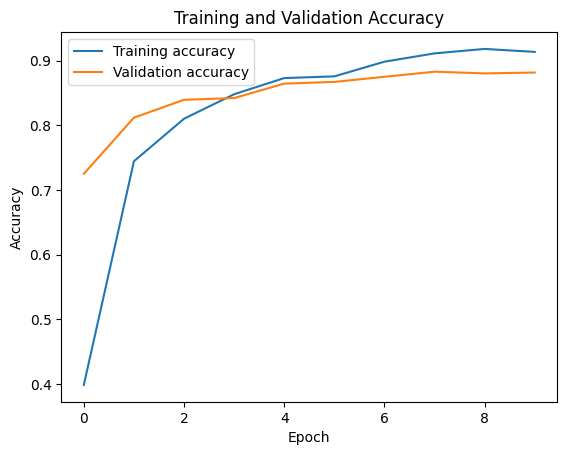

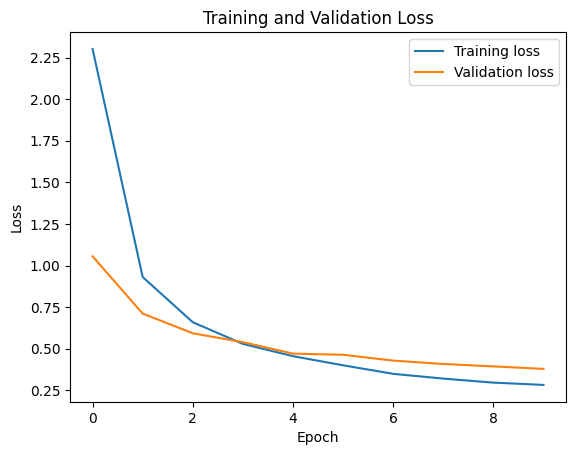

In [ ]:
plt.plot(history.history['accuracy'], label='Training accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.show()

plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.show()

In [ ]:
loss, acc = model.evaluate(X_val, y_val, verbose=0)
print(f"Validation accuracy: {acc*100:.2f}%")

Validation accuracy: 88.16%


In [ ]:
model.save('plant_disease_model.keras')
json.dump(list(le.classes_), open('class_names.json', 'w'))
print("Model saved successfully!")

Model saved successfully!


In [ ]:
!pip install -q gradio
import gradio as gr

def predict(img):
    img = cv2.resize(img, IMAGE_SIZE).astype("float32") / 255.0
    probs = model.predict(np.expand_dims(img, 0), verbose=0)[0]
    return {le.classes_[i]: float(probs[i]) for i in range(len(probs))}

gr.Interface(fn=predict,
             inputs=gr.Image(type="numpy"),
             outputs=gr.Label(num_top_classes=3),
             title="Crop Disease Diagnosis").launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://6a64de1dbe82bb148c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
